In [1]:
library(stringr)
library(GenomicRanges)
library(ggplot2)

library(Signac)
library(AnnotationHub)
library(rtracklayer)

library(reshape2)
library(ggrastr)
library(ggpubr)
library(cowplot)
library(patchwork)

library(EnsDb.Hsapiens.v86)

Loading required package: stats4

Loading required package: BiocGenerics


Attaching package: ‘BiocGenerics’


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, do.call, duplicated, eval, evalq, Filter, Find,
    get, grep, grepl, intersect, is.unsorted, lapply, Map, mapply,
    match, mget, order, paste, pmax, pmax.int, pmin, pmin.int,
    Position, rank, rbind, Reduce, rownames, sapply, setdiff, sort,
    table, tapply, union, unique, unsplit, which.max, which.min


Loading required package: S4Vectors


Attaching package: ‘S4Vectors’


The following object is masked from ‘package:utils’:

    findMatches


The following objects are masked from ‘package:base’:

    expand.grid, I, unname


Loading required package: IRanges

Loading required package: GenomeInfoDb

Loading required package: BiocFileCache

Loa

## Figure 1G-J 

### Library Statistics
First, reading in meta data on gRNAs (i.e. position of spacers). File derived from:

*https://doi.org/10.5281/zenodo.10456223*

Specifically, hg38-pELS/filtered_grnas.csv

In [2]:
pELS.gRNAs <- read.csv("../t7_mapping/v1_18K_K562/gRNA-pairs_K562-intronic-pELS.csv", header = TRUE, stringsAsFactors = FALSE)

pELS.gRNAs <- pELS.gRNAs[,c("g1_ccre_id","g1_cre_loc",
                            "g1_synthesis_sequence","g1_cutting_efficiency","g1_specificity",
                            "g2_synthesis_sequence","g2_cutting_efficiency","g2_specificity",
                              "g1_grna_start","g2_grna_start")]


colnames(pELS.gRNAs) <- c("CRE","peak","spacer1","spacer1_efficiency","spacer1_specificity",
                                       "spacer2","spacer2_efficiency","spacer2_specificity",
                                          "spacer1_start","spacer2_start")

pELS.gRNAs$both_spacers <- paste0(pELS.gRNAs$spacer1,"_",pELS.gRNAs$spacer2)

Reading in the oligo library that we ordered, adding the meta data information on the spacers from above, and using it to calculate the size of the programmed deletion made by the two spacer sequences:

In [3]:
oligos <- read.table("../t7_mapping/v1_18K_K562/v1_18K_twist-oligos.tsv", header=FALSE, sep=",")
colnames(oligos) <- c("del_id","oligo")

# Function to extract the 20 characters following a specific pattern
extract_spacer <- function(sequence, pattern) {
  match_pos <- str_locate(sequence, pattern)[,2] + 1
  spacer <- str_sub(sequence, match_pos, match_pos + 19)
  return(spacer)
}


# Extract spacers and add them to new columns
oligos$spacer1 <- sapply(oligos$oligo, extract_spacer, pattern = "aggacgaaacaccG")
oligos$spacer2 <- sapply(oligos$oligo, extract_spacer, pattern = "accggtactcagggatcc")

oligos$barcode <- sapply(oligos$oligo, extract_spacer, pattern = "ACGACTCACTATAGGGAAATAT")
oligos$barcode <- toupper(substr(oligos$barcode, 1, nchar(oligos$barcode) - 13))
oligos$both_spacers <- paste0(oligos$spacer1,"_",oligos$spacer2)

oligos$CRE <- pELS.gRNAs$peak[match(oligos$both_spacers,pELS.gRNAs$both_spacers)]
oligos$CRE_width <- sapply(strsplit(oligos$CRE, "-"), function(x) abs(as.numeric(x[2]) - as.numeric(x[3])))
                           
oligos$spacer1_start <- pELS.gRNAs$spacer1_start[match(oligos$both_spacers,pELS.gRNAs$both_spacers)]
oligos$spacer2_start <- pELS.gRNAs$spacer2_start[match(oligos$both_spacers,pELS.gRNAs$both_spacers)]
oligos$deletion_size <- abs(oligos$spacer1_start-oligos$spacer2_start) - 11
                           
oligos$deletion_percent <- 100*oligos$deletion_size / oligos$CRE_width

parts <- strsplit(oligos$CRE, "-")
oligos$CRE_chr   <- sapply(parts, `[`, 1)
oligos$CRE_start <- as.numeric(sapply(parts, `[`, 2))
oligos$CRE_end   <- as.numeric(sapply(parts, `[`, 3))

# Check whether each spacer is within the CRE range
oligos$spacer1_in_CRE <- oligos$spacer1_start >= oligos$CRE_start & 
                         oligos$spacer1_start <= oligos$CRE_end

oligos$spacer2_in_CRE <- oligos$spacer2_start >= oligos$CRE_start & 
                         oligos$spacer2_start <= oligos$CRE_end

Visualizing the distribution of programmed deletion sizes, and the percentage of the annotated CRE that each deletion should be removing:

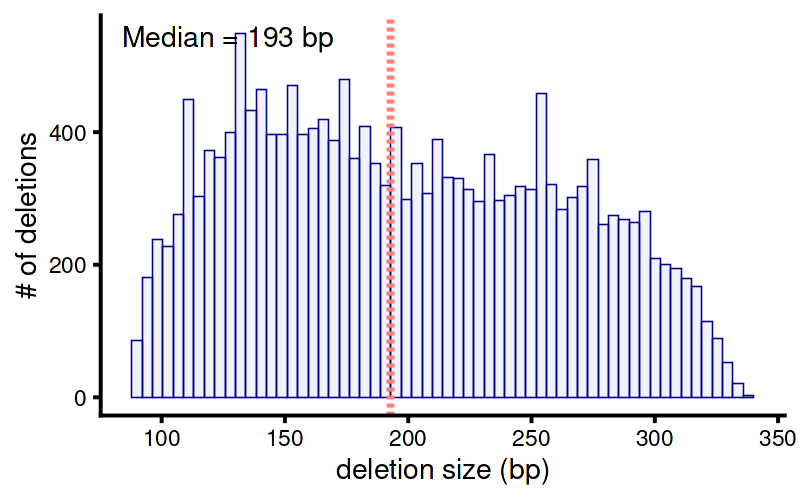

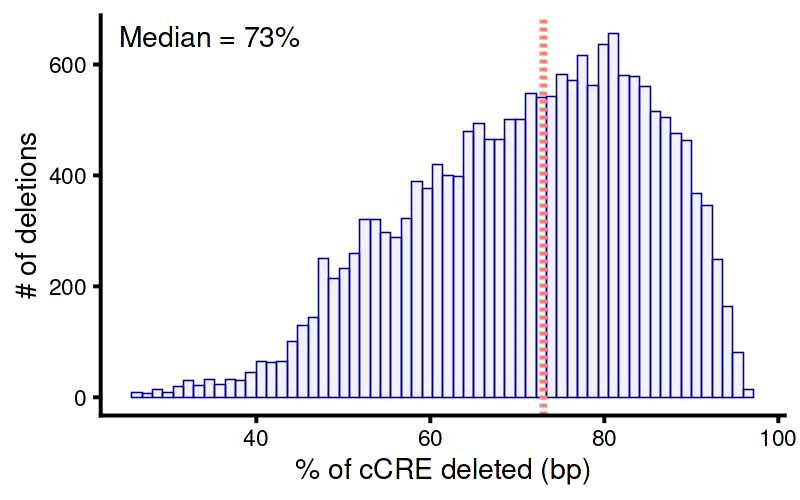

In [4]:
median_size <- round(median(oligos[!grepl("NTC", oligos$del_id), ]$deletion_size), 2)
h <- ggplot(oligos[!grepl("NTC", oligos$del_id), ], aes(x = deletion_size)) + 
  geom_histogram(bins = 60, colour = "darkblue", fill = "#d5d5ff", alpha = 0.3,linewidth=.2) + 
  theme_classic() + 
  xlab("deletion size (bp)") + ylab("# of deletions") +
  theme(text = element_text(size = 10),
              axis.title = element_text(size = 10),
              axis.text = element_text(size = 8)) +
  geom_vline(xintercept=median_size,
             linetype="dashed",color="salmon",linewidth=1) + 
  annotate(
    "text", 
    x = -Inf,          # top-left corner horizontally
    y = Inf,           # top edge vertically
    hjust = -0.1,      # nudge it slightly inside the plot from the left
    vjust = 1.5,         # nudge it slightly down from the top
    label = paste0("Median = ", median_size," bp"),
    color = "black",size=10/.pt
  )


median_percent <- round(median(oligos[!grepl("NTC", oligos$del_id), ]$deletion_percent), 2)
i <- ggplot(oligos[!grepl("NTC", oligos$del_id), ], aes(x = deletion_percent)) + 
  geom_histogram(bins = 60, colour = "darkblue", fill = "#d5d5ff", alpha = 0.3,linewidth=.2) + 
  theme_classic() + 
  xlab("% of cCRE deleted (bp)") + ylab("# of deletions") +
  theme(text = element_text(size = 10),
              axis.title = element_text(size = 10),
              axis.text = element_text(size = 8))+
  geom_vline(xintercept=median_percent,
             linetype="dashed",color="salmon",linewidth=1)+ 
  annotate(
    "text", 
    x = -Inf,          # top-left corner horizontally
    y = Inf,           # top edge vertically
    hjust = -0.1,      # nudge it slightly inside the plot from the left
    vjust = 1.5,         # nudge it slightly down from the top
    label = paste0("Median = ", signif(median_percent,2),"%"),
    color = "black",size=10/.pt
  )

options(repr.plot.width = 4, repr.plot.height = 2.5, repr.plot.res = 200)
h
i

Next, reading in gtf file with gene annotation informaiton, and subsetting it to transcripts (and exons):

In [5]:
gtf_file <- "../../19K-intronic_K562-3N-3d-T7/gencode.v44.basic.annotation.gtf"
gtf <- import(gtf_file) 

transcripts_gr <- subset(
  gtf,
  type == "transcript"
)

exons_gr <- subset(
  gtf,
  type == "exon"
)


Function to convert a string to a GRanges object:

In [6]:
sites_granges <- function(sites) {
  # Split each element in the vector by '-' and create a data frame
  site_df <- data.frame(do.call(rbind, strsplit(sites, "-")), stringsAsFactors = FALSE)
  
  # Rename the columns to "seqnames", "start", and "end"
  colnames(site_df) <- c("seqnames", "start", "end")
  
  # Convert the "start" and "end" columns to numeric
  site_df$start <- as.numeric(site_df$start)
  site_df$end   <- as.numeric(site_df$end)
  
  # Create a GRanges object from the data frame
  gr <- makeGRangesFromDataFrame(site_df)
  return(gr)
}

Getting the location of each cCRE that we are targeting, and seeing what gene it overlaps:

In [7]:
# 1) Convert your CRE strings to GRanges
oligo_gr <- sites_granges(oligos[grepl("EH38",oligos$del_id) == TRUE,]$CRE)

# 2) Find overlaps between CREs and transcripts
hits <- findOverlaps(oligo_gr, transcripts_gr)

# Convert the hits to a data.frame for easier manipulation
hits_df <- as.data.frame(hits)
# Order by query index so the first hit for each CRE appears first
hits_df <- hits_df[order(hits_df$queryHits), ]
# For each CRE, select only the first overlapping transcript
first_hits <- hits_df[!duplicated(hits_df$queryHits), ]

# 3) Create a new column in 'oligos' (default NA)
oligos$gene <- NA

# Use the query index from first_hits to update 'oligos$gene'
oligos$gene[first_hits$queryHits] <- mcols(transcripts_gr)$gene_id[first_hits$subjectHits]

oligos$gene <- sub("\\..*", "", oligos$gene)


# Check the updated dataframe
head(oligos)

,del_id,oligo,spacer1,spacer2,barcode,both_spacers,CRE,CRE_width,spacer1_start,spacer2_start,deletion_size,deletion_percent,CRE_chr,CRE_start,CRE_end,spacer1_in_CRE,spacer2_in_CRE,gene
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<int>,<int>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<lgl>,<lgl>,<chr>
1,EH38D0217608_D232u,aggacgaaacaccGTGAGTCCACCACTTCCATGAgtttAagagctagaaatagcaagttTaaataaggctagtccgttatcaacttgaaaaagtggcaccgagtcggtgcTATTTCCCTATAGTGAGTCGTATTAAATTGCTGTGCTACTGGCACTGGAAGTGGTGGAaccggtactcagggatccTCATATATTCAATACACGTAgtttAagagctagaaatagcaagttTaaataaggctagtccgttatcaacttgaaaaagtggcaccgagtcggtgcACGACTCACTATAGGGAAATATGAGCGACTGCTAGTTGTGCTTTCCGCGTGTGTATTGAATATttgacgcggttctat,TGAGTCCACCACTTCCATGA,TCATATATTCAATACACGTA,GAGCGAC,TGAGTCCACCACTTCCATGA_TCATATATTCAATACACGTA,chr10-51700443-51700779,336,51700478,51700710,221,65.77381,chr10,51700443,51700779,TRUE,TRUE,ENSG00000185532
2,EH38D0217608_D217X,aggacgaaacaccGGAGTCCACCACTTCCATGAAgtttAagagctagaaatagcaagttTaaataaggctagtccgttatcaacttgaaaaagtggcaccgagtcggtgcTATTTCCCTATAGTGAGTCGTATTAAATTGCTGTGCTACTGGCACATGGAAGTGGTGGaccggtactcagggatccCACGTAAGGCAGTGTAGAATgtttAagagctagaaatagcaagttTaaataaggctagtccgttatcaacttgaaaaagtggcaccgagtcggtgcACGACTCACTATAGGGAAATATGTCTCACCGATAGTTGTGCTTTCCGCGTCTACACTGCCTTAttgacgcggttctat,GAGTCCACCACTTCCATGAA,CACGTAAGGCAGTGTAGAAT,GTCTCAC,GAGTCCACCACTTCCATGAA_CACGTAAGGCAGTGTAGAAT,chr10-51700443-51700779,336,51700479,51700696,206,61.30952,chr10,51700443,51700779,TRUE,TRUE,ENSG00000185532
3,EH38D0217608_D218z,aggacgaaacaccGTGAGTCCACCACTTCCATGAgtttAagagctagaaatagcaagttTaaataaggctagtccgttatcaacttgaaaaagtggcaccgagtcggtgcTATTTCCCTATAGTGAGTCGTATTAAATTGCTGTGCTACTGGCACTGGAAGTGGTGGAaccggtactcagggatccCACGTAAGGCAGTGTAGAATgtttAagagctagaaatagcaagttTaaataaggctagtccgttatcaacttgaaaaagtggcaccgagtcggtgcACGACTCACTATAGGGAAATATGTCTCGTTTCTAGTTGTGCTTTCCGCGTCTACACTGCCTTAttgacgcggttctat,TGAGTCCACCACTTCCATGA,CACGTAAGGCAGTGTAGAAT,GTCTCGT,TGAGTCCACCACTTCCATGA_CACGTAAGGCAGTGTAGAAT,chr10-51700443-51700779,336,51700478,51700696,207,61.60714,chr10,51700443,51700779,TRUE,TRUE,ENSG00000185532
4,EH38D0217608_D231b,aggacgaaacaccGGAGTCCACCACTTCCATGAAgtttAagagctagaaatagcaagttTaaataaggctagtccgttatcaacttgaaaaagtggcaccgagtcggtgcTATTTCCCTATAGTGAGTCGTATTAAATTGCTGTGCTACTGGCACATGGAAGTGGTGGaccggtactcagggatccTCATATATTCAATACACGTAgtttAagagctagaaatagcaagttTaaataaggctagtccgttatcaacttgaaaaagtggcaccgagtcggtgcACGACTCACTATAGGGAAATATGTCGCTGGGCTAGTTGTGCTTTCCGCGTGTGTATTGAATATttgacgcggttctat,GAGTCCACCACTTCCATGAA,TCATATATTCAATACACGTA,GTCGCTG,GAGTCCACCACTTCCATGAA_TCATATATTCAATACACGTA,chr10-51700443-51700779,336,51700479,51700710,220,65.47619,chr10,51700443,51700779,TRUE,TRUE,ENSG00000185532
5,EH38D2115973_D134m,aggacgaaacaccGCATCTCCAAATCCTACTAACgtttAagagctagaaatagcaagttTaaataaggctagtccgttatcaacttgaaaaagtggcaccgagtcggtgcTATTTCCCTATAGTGAGTCGTATTAAATTGCTGTGCTACTGGCACAGTAGGATTTGGAaccggtactcagggatccCTACGAATGCCACCGGGAAAgtttAagagctagaaatagcaagttTaaataaggctagtccgttatcaacttgaaaaagtggcaccgagtcggtgcACGACTCACTATAGGGAAATATATCTCAGCAATAGTTGTGCTTTCCGCGTCCCGGTGGCATTCttgacgcggttctat,CATCTCCAAATCCTACTAAC,CTACGAATGCCACCGGGAAA,ATCTCAG,CATCTCCAAATCCTACTAAC_CTACGAATGCCACCGGGAAA,chr1-1231471-1231625,154,1231486,1231620,123,79.87013,chr1,1231471,1231625,TRUE,TRUE,ENSG00000078808
6,EH38D2115973_D130Q,aggacgaaacaccGATCTCCAAATCCTACTAACTgtttAagagctagaaatagcaagttTaaataaggctagtccgttatcaacttgaaaaagtggcaccgagtcggtgcTATTTCCCTATAGTGAGTCGTATTAAATTGCTGTGCTACTGGCACTAGTAGGATTTGGaccggtactcagggatccCGAATGCCACCGGGAAACGGgtttAagagctagaaatagcaagttTaaataaggctagtccgttatcaacttgaaaaagtggcaccgagtcggtgcACGACTCACTATAGGGAAATATTATGGAGGGCTAGTTGTGCTTTCCGCGTTTTCCCGGTGGCAttgacgcggttctat,ATCTCCAAATCCTACTAACT,CGAATGCCACCGGGAAACGG,TATGGAG,ATCTCCAAATCCTACTAACT_CGAATGCCACCGGGAAACGG,chr1-1231471-1231625,154,1231487,1231617,119,77.27273,chr1,1231471,1231625,TRUE,TRUE,ENSG00000078808


Reading in K562 TPM data from Xiaoyi. Each gene had 3 replicates, so we are just taking the average of each replicate:

In [8]:
K562_exp <- read.csv("../../19K-intronic_K562-3N-3d-T7/K562_WT_TPM.csv",header=TRUE,sep=",")

colnames(K562_exp) <- c("gene","R1","R2","R3")


K562_average <- K562_exp
K562_average$mean <- rowMeans(K562_exp[, c("R1", "R2", "R3")])
K562_average$median <- apply(K562_exp[, c("R1", "R2", "R3")], 1, median)
K562_average <- K562_average[, c("gene", "mean", "median")]

K562_exp <- melt(K562_exp, id.vars = "gene", 
                      variable.name = "replicate", 
                      value.name = "count")

Visualizing the TPM of genes that the CREs we are targeting overlap, vs all other genes:

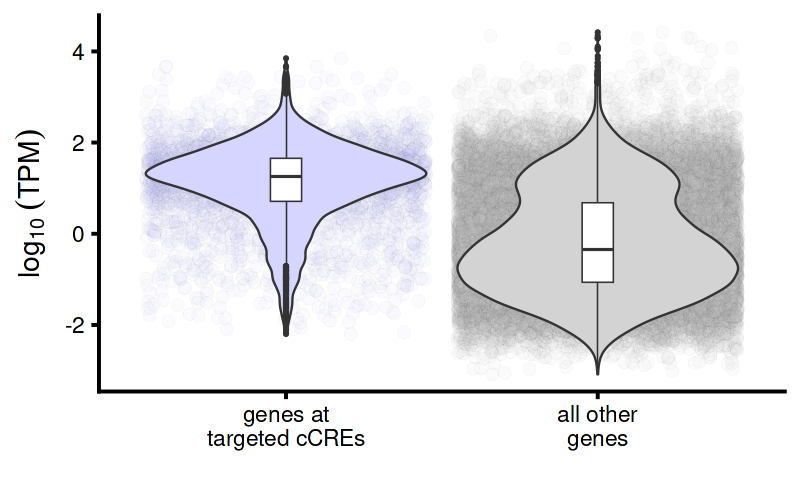

In [9]:
K562_average$type <- ifelse(K562_average$gene %in% 
                            oligos$gene, "genes at\ntargeted cCREs",
#                      ifelse(K562_average$gene %in% 
#                             top_100$gene, "top 100 screen",      
                            "all other\ngenes")

K562_average$type <- factor(K562_average$type, levels = c("genes at\ntargeted cCREs", 
                                                          "all other\ngenes"))


j <- ggplot(K562_average[K562_average$mean > 0,],aes(x=type,y=log10(mean),fill=type)) + 
  geom_jitter_rast(width=.45,alpha=.05,shape=21,stroke=.1,color="black",size=2) + 
  geom_violin(scale = "width",linewidth = .3) + 
  geom_boxplot(width=.1,fill="white",linewidth = .2,outlier.size=.1) +
  theme_classic() + 
  scale_fill_manual(values=c("#d5d5ff","lightgrey")) +
  xlab("") + 
  ylab(bquote(log[10]~("TPM"))) + theme(text = element_text(size = 10),
              axis.title = element_text(size = 10),
              axis.text = element_text(size = 8),legend.position="none")

options(repr.plot.width = 4, repr.plot.height = 2.5, repr.plot.res = 200)
j

Visualizing the distance of each CRE to the nearest TSS. First, getting distance to nearest TSS:

In [10]:
oligo_gr <- unique(oligo_gr)

gtf.transcripts <- gtf[mcols(gtf)$type == "transcript"]

tss.gr <- resize(gtf.transcripts, width = 1, fix = "start")
mcols(tss.gr)$gene_name <- mcols(gtf.transcripts)$gene_name
mcols(tss.gr)$gene_id   <- mcols(gtf.transcripts)$gene_id

# nearest TSS for each oligo
hits <- distanceToNearest(oligo_gr, tss.gr, ignore.strand = TRUE)

# indices
q <- queryHits(hits)
s <- subjectHits(hits)

# unsigned distances
d <- mcols(hits)$distance

# initialize output
signed_dist <- rep(NA_integer_, length(oligo_gr))

# extract relevant pieces
oligo_sub <- oligo_gr[q]
tss_sub   <- tss.gr[s]

tss_pos    <- start(tss_sub)   # 1-bp TSS
tss_strand <- as.character(strand(tss_sub))

oligo_start <- start(oligo_sub)
oligo_end   <- end(oligo_sub)

# overlap / contains TSS -> distance 0
is_zero <- oligo_start <= tss_pos & oligo_end >= tss_pos

# plus-strand genes
plus_up   <- tss_strand == "+" & oligo_end   < tss_pos
plus_down <- tss_strand == "+" & oligo_start > tss_pos

# minus-strand genes
minus_up   <- tss_strand == "-" & oligo_start > tss_pos
minus_down <- tss_strand == "-" & oligo_end   < tss_pos

signed_d_sub <- d
signed_d_sub[is_zero]    <- 0L
signed_d_sub[plus_up]    <- -d[plus_up]
signed_d_sub[plus_down]  <-  d[plus_down]
signed_d_sub[minus_up]   <- -d[minus_up]
signed_d_sub[minus_down] <-  d[minus_down]

signed_dist[q] <- signed_d_sub

mcols(oligo_gr)$nearest_tss_dist_signed <- signed_dist
mcols(oligo_gr)$nearest_tss_gene <- NA_character_
mcols(oligo_gr)$nearest_tss_gene[q] <- tss.gr$gene_name[s]

nearest_tss_df <- data.frame(
  oligo_range = paste0(
    as.character(seqnames(oligo_sub)), "-",
    start(oligo_sub), "-",
    end(oligo_sub)
  ),
  gene_name = tss_sub$gene_name,
  gene_id = tss_sub$gene_id,
  gene_strand = tss_strand,
  signed_distance = signed_d_sub,
  stringsAsFactors = FALSE
)

Plot the distance as a histogram:

Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on 'Downstream ≤ 2 kb: 78%' in 'mbcsToSbcs': dot substituted for <e2>"
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on 'Downstream ≤ 2 kb: 78%' in 'mbcsToSbcs': dot substituted for <89>"
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on 'Downstream ≤ 2 kb: 78%' in 'mbcsToSbcs': dot substituted for <a4>"


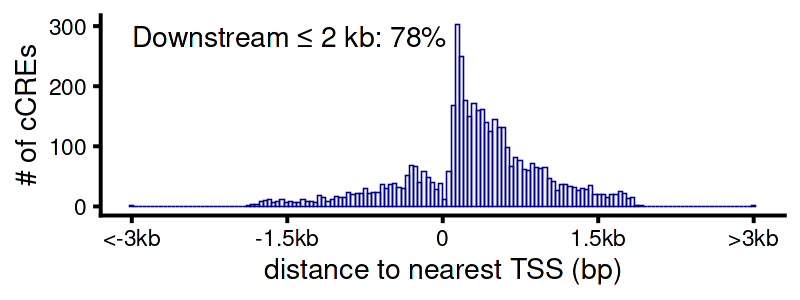

In [11]:
p_downstream <- signif(nrow(nearest_tss_df[
  abs(nearest_tss_df$signed_distance) <= 2000 &
  nearest_tss_df$signed_distance >= 0, ]) / nrow(nearest_tss_df),2)

plot.df <- nearest_tss_df

plot.df$signed_distance <- ifelse(
  plot.df$signed_distance > 3000, 3000,
  ifelse(plot.df$signed_distance < -3000, -3000, plot.df$signed_distance)
)

hist <- hist(plot.df$signed_distance, breaks = 150, plot = FALSE)
ymax <- max(hist$counts)

options(repr.plot.width = 4, repr.plot.height = 1.5, repr.plot.res = 200)

g <- ggplot(plot.df, aes(x = signed_distance)) +
  geom_histogram(bins = 150, colour = "darkblue", fill = "#d5d5ff", alpha = 0.3,linewidth=.2) +
  coord_cartesian(xlim = c(-3000, 3000)) +
  scale_x_continuous(
    breaks = c(-3000, -1500, 0, 1500, 3000),
    labels = c("<-3kb", "-1.5kb", "0", "1.5kb", ">3kb")) +
  xlab("distance to nearest TSS (bp)") +
  theme_classic() +
  theme(text = element_text(size = 10),
              axis.title = element_text(size = 10),
              axis.text = element_text(size = 8)) +
  annotate(
    "text",
    x = -3000,
    y = Inf,
    label = paste0("Downstream ≤ 2 kb: ", round(p_downstream * 100, 1), "%"),
    vjust = 1.5,
    hjust = 0,size=10/.pt
  ) + ylab("# of cCREs")

g 

Adding all plots into one:

Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on 'Downstream ≤ 2 kb: 78%' in 'mbcsToSbcs': dot substituted for <e2>"
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on 'Downstream ≤ 2 kb: 78%' in 'mbcsToSbcs': dot substituted for <89>"
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on 'Downstream ≤ 2 kb: 78%' in 'mbcsToSbcs': dot substituted for <a4>"


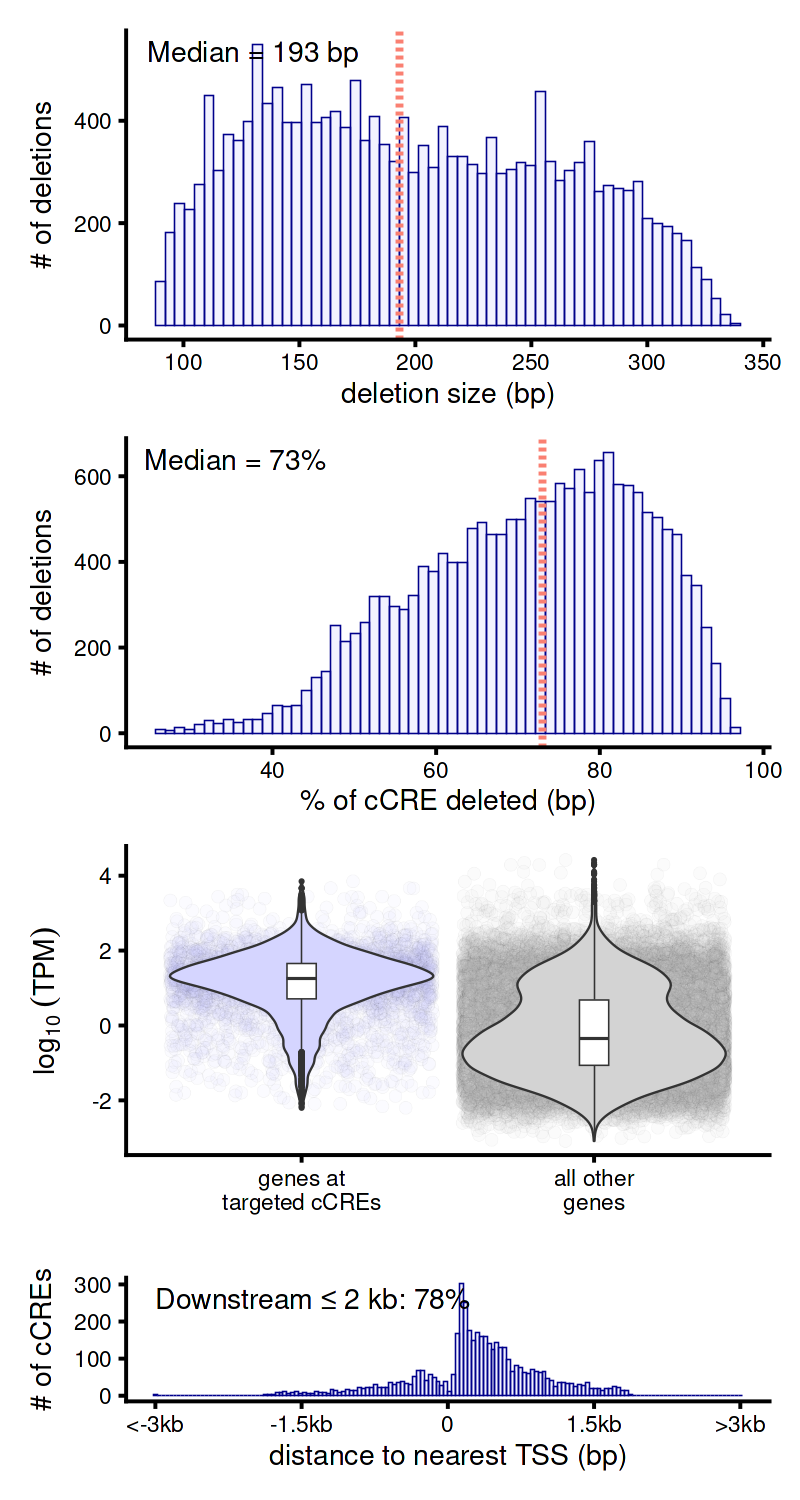

In [12]:
layout <- 'A
           B
           C
           D
           '

fig <-  h + i + j + g +
  plot_layout(
    design = layout,
    heights = c(1, 1, 1,0.4)
  )


options(repr.plot.width = 4, repr.plot.height = 7.5, repr.plot.res = 200)
fig

In [13]:
ggsave('../figures/Figure1G-J.pdf', plot = fig, width = 65, height = 140, useDingbats = F, units = 'mm', device = 'pdf')

Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on 'Downstream ≤ 2 kb: 78%' in 'mbcsToSbcs': dot substituted for <e2>"
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on 'Downstream ≤ 2 kb: 78%' in 'mbcsToSbcs': dot substituted for <89>"
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on 'Downstream ≤ 2 kb: 78%' in 'mbcsToSbcs': dot substituted for <a4>"
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on 'Downstream ≤ 2 kb: 78%' in 'mbcsToSbcs': dot substituted for <e2>"
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on 'Downstream ≤ 2 kb: 78%' in 'mbcsToSbcs': dot substituted for <89>"
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on 'Downstream 

In [14]:
sessionInfo()

R version 4.3.2 (2023-10-31)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 22.04.4 LTS

Matrix products: default
BLAS:   /net/gs/vol3/software/modules-sw/R/4.3.2/Linux/Ubuntu22.04/x86_64/lib/R/lib/libRblas.so 
LAPACK: /net/gs/vol3/software/modules-sw/R/4.3.2/Linux/Ubuntu22.04/x86_64/lib/R/lib/libRlapack.so;  LAPACK version 3.11.0

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

time zone: America/Los_Angeles
tzcode source: system (glibc)

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] EnsDb.Hsapiens.v86_2.99.0 ensembldb_2.26.0         
 [3] AnnotationFilter_1.26.0   GenomicFeatures_1.54.4   
 [5] AnnotationDbi_1.64.1      Bi